Evaluate the classification model using accuracy, precision, recall, and F1-score by computing additional metrics such as Cohen?s Kappa and Matthews Correlation Coefficient, analyzing precision-recall trade-offs, and visualizing ROC-AUC curves.

In [8]:

import joblib
import os

save_folder = "task31_saved_files"

model_l1 = joblib.load(os.path.join(save_folder, "logistic_regression_l1.pkl"))

model_l2 = joblib.load(os.path.join(save_folder, "logistic_regression_l2.pkl"))

preprocessor = joblib.load(os.path.join(save_folder, "preprocessor.pkl"))

feature_config = joblib.load(os.path.join(save_folder, "feature_config.pkl"))

print("Models and preprocessing loaded successfully!")
print("Target:", feature_config["target_column"])


Models and preprocessing loaded successfully!
Target: recommend_flag


In [9]:
print("L1 model:", type(model_l1))
print("Preprocessor:", type(preprocessor))
print("L2 model available:", "model_l2" in globals())

L1 model: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
L2 model available: True


In [11]:
x_test = joblib.load(os.path.join(save_folder, 'x_test.pkl'))
y_test = joblib.load(os.path.join(save_folder, 'y_test.pkl'))

In [12]:
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

print("\nTarget distribution:")
print(y_test.value_counts())

print("\nFeature columns:")
print(x_test.columns.tolist())

x_test shape: (4697, 15)
y_test shape: (4697,)

Target distribution:
recommend_flag
1    3863
0     834
Name: count, dtype: int64

Feature columns:
['customer_age', 'rating', 'vader_negative', 'vader_neutral', 'vader_positive', 'vader_compound', 'vader_sentiment_score', 'category', 'subcategory1', 'subcategory2', 'location', 'channel', 'age_group', 'vader_sentiment_label', 'model_text']


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, roc_auc_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve, average_precision_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

Transform test data and generate predictions

In [17]:
x_test_processed = preprocessor.transform(x_test)
print("Processed test shape:", x_test_processed.shape)

models = {
    "Logistic Regression L1": model_l1,
    "Logistic Regression L2": model_l2,
}
evalution_res = {}

for name, model in models.items():
    y_pred = model.predict(x_test_processed)

    y_prob = model.predict_proba(x_test_processed)[:, 1]

    evalution_res[name] = {
        'y_pred': y_pred,
        'y_prob': y_prob
    }

print("\nPredictions generated successfully!")

Processed test shape: (4697, 3049)

Predictions generated successfully!


Calculate all required metrics

In [20]:
results = []

for name, result in evalution_res.items():

    y_pred = result['y_pred']
    y_prob = result['y_prob']

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "Cohen's Kappa": cohen_kappa_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_pred),
        "Average Precision": average_precision_score(y_test, y_pred)
    })

evaluation_df = pd.DataFrame(results)
print("CLASSIFICATION MODEL EVALUATION")
display(evaluation_df.round(4))

CLASSIFICATION MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1 Score,Cohen's Kappa,MCC,ROC-AUC,Average Precision
0,Logistic Regression L1,0.9402,0.9843,0.9423,0.9628,0.8099,0.815,0.9364,0.9750
1,Logistic Regression L2,0.9402,0.9862,0.9405,0.9628,0.8111,0.817,0.9397,0.9764


Confusion matrices and classification reports


Logistic Regression L1
--------------------------------------------------
                 precision    recall  f1-score   support

Not Recommended       0.78      0.93      0.85       834
    Recommended       0.98      0.94      0.96      3863

       accuracy                           0.94      4697
      macro avg       0.88      0.94      0.90      4697
   weighted avg       0.95      0.94      0.94      4697



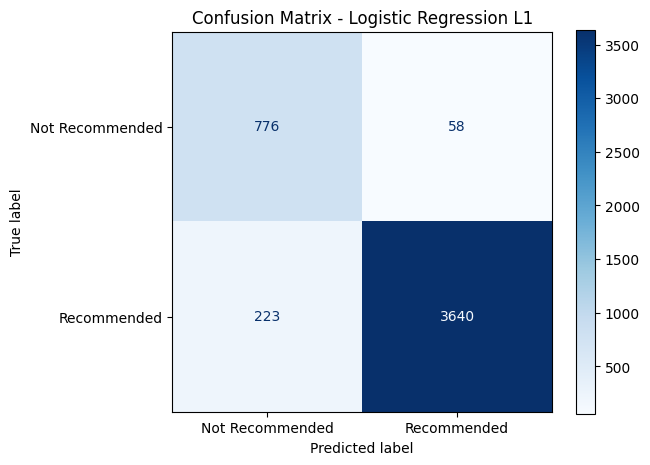


Logistic Regression L2
--------------------------------------------------
                 precision    recall  f1-score   support

Not Recommended       0.77      0.94      0.85       834
    Recommended       0.99      0.94      0.96      3863

       accuracy                           0.94      4697
      macro avg       0.88      0.94      0.91      4697
   weighted avg       0.95      0.94      0.94      4697



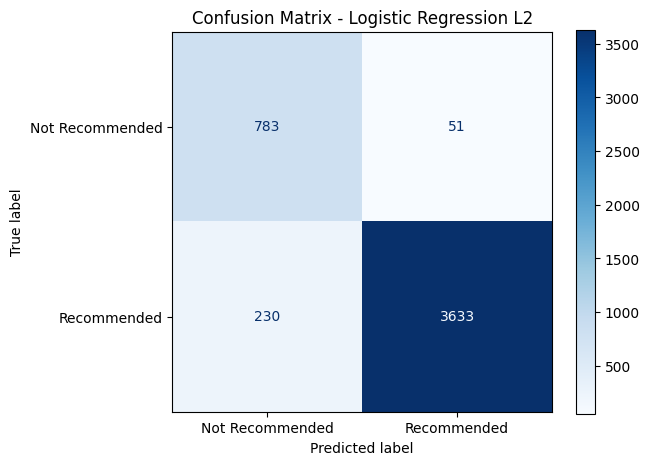

In [21]:
for name, result in evalution_res.items():

    print(f"\n{name}")
    print("-"*50)

    print(classification_report(y_test, result['y_pred'], target_names=["Not Recommended", "Recommended"], zero_division=0))

    cm = confusion_matrix(y_test, result['y_pred'])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Recommended", "Recommended"])

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

ROC-AUC curve

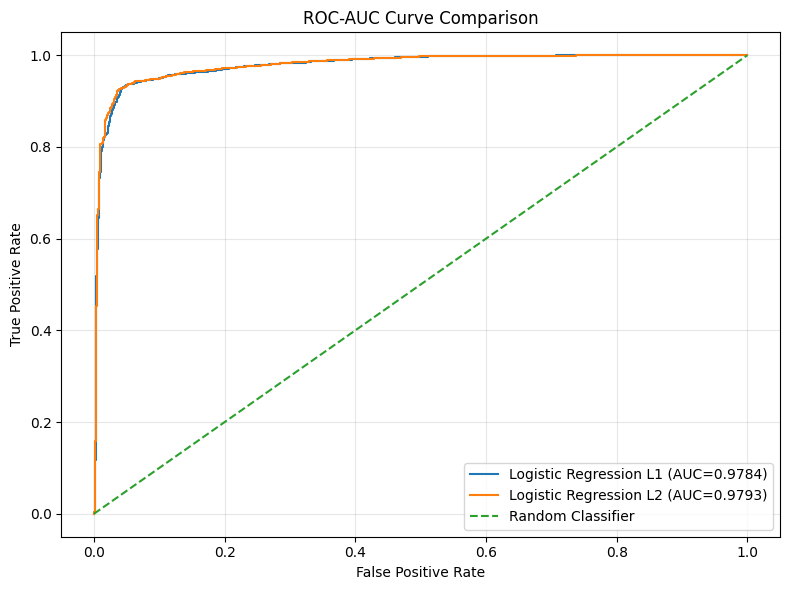

In [22]:
plt.figure(figsize=(8, 6))

for name, result in evalution_res.items():
    fpr, tpr, _ = roc_curve(y_test, result['y_prob'])
    auc_value = roc_auc_score(y_test, result['y_prob'])

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.4f})")

plt.plot([0, 1], [0, 1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Precision–Recall trade-off

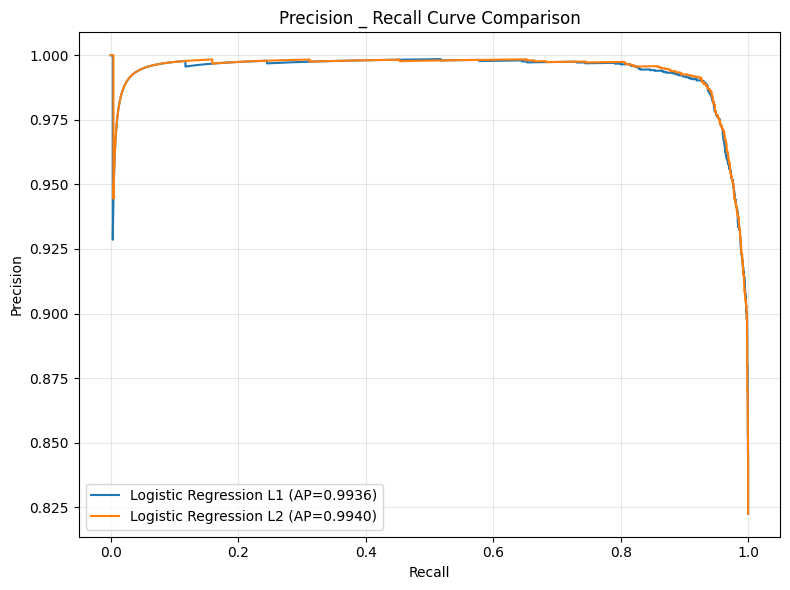

In [23]:
plt.figure(figsize=(8, 6))

for name, result in evalution_res.items():
    precision, recall, _ = precision_recall_curve(y_test, result['y_prob'])

    ap = average_precision_score(y_test, result['y_prob'])

    plt.plot(recall, precision, label=f"{name} (AP={ap:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision _ Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
for name, result in evalution_res.items():
    y_prob = result['y_prob']
    print(f"\n{name}")
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))
    print("Average Precision:", average_precision_score(y_test, y_prob))


Logistic Regression L1
ROC-AUC: 0.9783741218260184
Average Precision: 0.9935963369990831

Logistic Regression L2
ROC-AUC: 0.9792813949720369
Average Precision: 0.9939918472481046


In [25]:
for i, name in enumerate(evalution_res.keys()):
    y_prob = evalution_res[name]['y_prob']

    evaluation_df.loc[i, 'ROC-AUC'] = roc_auc_score(y_test, y_prob)

    evaluation_df.loc[i, 'Average Precision'] = average_precision_score(y_test, y_prob)
display(evaluation_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,Cohen's Kappa,MCC,ROC-AUC,Average Precision
0,Logistic Regression L1,0.9402,0.9843,0.9423,0.9628,0.8099,0.815,0.9784,0.9936
1,Logistic Regression L2,0.9402,0.9862,0.9405,0.9628,0.8111,0.817,0.9793,0.9940
